In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [59]:
print("Loading Credit Dataset...")

data = fetch_openml(
    name="credit-g",
    version=1,
    as_frame=True
)

df = data.frame

print("Dataset loaded successfully!")

Loading Credit Dataset...
Dataset loaded successfully!


In [60]:
display(df.head())

print("Dataset Shape:", df.shape)

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


Dataset Shape: (1000, 21)


In [61]:
# Check missing values in each column

print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
checking_status           0
duration                  0
credit_history            0
purpose                   0
credit_amount             0
savings_status            0
employment                0
installment_commitment    0
personal_status           0
other_parties             0
residence_since           0
property_magnitude        0
age                       0
other_payment_plans       0
housing                   0
existing_credits          0
job                       0
num_dependents            0
own_telephone             0
foreign_worker            0
class                     0
dtype: int64

Total Missing Values:
0


In [62]:
print("Dataset Information:")
df.info()



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   category
 14  hous

In [63]:
print("Credit Risk Distribution:")
print(df['class'].value_counts())

Credit Risk Distribution:
class
good    700
bad     300
Name: count, dtype: int64


In [64]:
# Convert categorical columns into numerical columns

df_encoded = pd.get_dummies(df, drop_first=True)

print("Encoded Dataset:")
print(df_encoded.head())

print("\nNew Dataset Shape:")
print(df_encoded.shape)

Encoded Dataset:
   duration  credit_amount  installment_commitment  residence_since  age  \
0         6           1169                       4                4   67   
1        48           5951                       2                2   22   
2        12           2096                       2                3   49   
3        42           7882                       2                4   45   
4        24           4870                       3                4   53   

   existing_credits  num_dependents  checking_status_<0  \
0                 2               1                True   
1                 1               1               False   
2                 1               2               False   
3                 1               2                True   
4                 2               2                True   

   checking_status_>=200  checking_status_no checking  ...  \
0                  False                        False  ...   
1                  False                       

In [65]:
# Separate input and output data

X = df_encoded.drop('class_good', axis=1)
y = df['class'].map({'good': 1, 'bad': 0})

print("Input Data Shape:", X.shape)
print("Output Data Shape:", y.shape)

print("\nTarget Values:")
print(y.value_counts())

Input Data Shape: (1000, 48)
Output Data Shape: (1000,)

Target Values:
class
1    700
0    300
Name: count, dtype: int64


In [66]:
from sklearn.model_selection import train_test_split

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (800, 48)
Testing Data: (200, 48)
Training Target: (800,)
Testing Target: (200,)


In [67]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Scale the input data
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create the model
model = LogisticRegression(max_iter=3000)

# Train the model
model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")



Logistic Regression Model Trained Successfully!


In [68]:
from sklearn.metrics import accuracy_score

# Predict test data
y_pred = model.predict(X_test_scaled)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")



Model Accuracy: 70.5 %


In [69]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Bad Credit', 'Good Credit']
))

Classification Report:
              precision    recall  f1-score   support

  Bad Credit       0.51      0.45      0.48        60
 Good Credit       0.78      0.81      0.79       140

    accuracy                           0.70       200
   macro avg       0.64      0.63      0.64       200
weighted avg       0.70      0.70      0.70       200



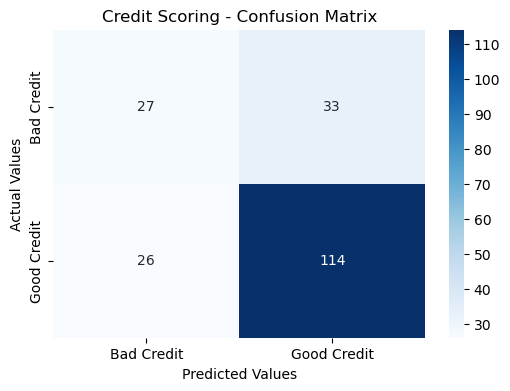

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Bad Credit', 'Good Credit'],
    yticklabels=['Bad Credit', 'Good Credit']
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Credit Scoring - Confusion Matrix")
plt.show()

In [71]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [72]:
from sklearn.metrics import accuracy_score

# Predict test data
rf_pred = rf_model.predict(X_test)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy * 100, "%")

Random Forest Accuracy: 72.5 %


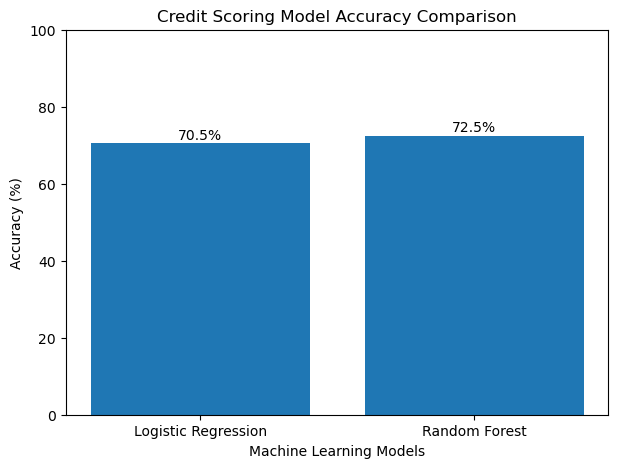

In [73]:
models = ['Logistic Regression', 'Random Forest']
accuracies = [accuracy * 100, rf_accuracy * 100]

plt.figure(figsize=(7, 5))
plt.bar(models, accuracies)

plt.title("Credit Scoring Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center')

plt.show()

In [74]:
import joblib

# Save Random Forest model and scaler
joblib.dump(rf_model, 'credit_scoring_model.pkl')
joblib.dump(scaler, 'credit_scaler.pkl')

print("Model saved successfully!")

Model saved successfully!


In [75]:
# Test prediction using a sample customer

sample = X_test.iloc[[0]]

prediction = rf_model.predict(sample)

if prediction[0] == 1:
    print("Credit Risk: GOOD")
else:
    print("Credit Risk: BAD")

Credit Risk: GOOD
